Laboratory Work 3
Name: OTHMAN ABDULLAH
Group: (25-ИИ-1)

In [201]:
!pip install scikit-learn

In [202]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [203]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

In [204]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [205]:
print(housing.data[0:10])

[[ 8.32520000e+00  4.10000000e+01  6.98412698e+00  1.02380952e+00
   3.22000000e+02  2.55555556e+00  3.78800000e+01 -1.22230000e+02]
 [ 8.30140000e+00  2.10000000e+01  6.23813708e+00  9.71880492e-01
   2.40100000e+03  2.10984183e+00  3.78600000e+01 -1.22220000e+02]
 [ 7.25740000e+00  5.20000000e+01  8.28813559e+00  1.07344633e+00
   4.96000000e+02  2.80225989e+00  3.78500000e+01 -1.22240000e+02]
 [ 5.64310000e+00  5.20000000e+01  5.81735160e+00  1.07305936e+00
   5.58000000e+02  2.54794521e+00  3.78500000e+01 -1.22250000e+02]
 [ 3.84620000e+00  5.20000000e+01  6.28185328e+00  1.08108108e+00
   5.65000000e+02  2.18146718e+00  3.78500000e+01 -1.22250000e+02]
 [ 4.03680000e+00  5.20000000e+01  4.76165803e+00  1.10362694e+00
   4.13000000e+02  2.13989637e+00  3.78500000e+01 -1.22250000e+02]
 [ 3.65910000e+00  5.20000000e+01  4.93190661e+00  9.51361868e-01
   1.09400000e+03  2.12840467e+00  3.78400000e+01 -1.22250000e+02]
 [ 3.12000000e+00  5.20000000e+01  4.79752705e+00  1.06182380e+00
   

In [206]:
print(housing.target[0:10])

[4.526 3.585 3.521 3.413 3.422 2.697 2.992 2.414 2.267 2.611]


In [207]:
X = housing.data
y = housing.target

In [208]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)

In [209]:
print(len(X_train))
print(len(X_test))

16512
4128


In [210]:
from sklearn.linear_model import LinearRegression

model_linear = LinearRegression()
model_linear.fit(X_train, y_train)

LinearRegression()

In [211]:
y_pred_linear = model_linear.predict(X_test)

In [212]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [213]:
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

LinearRegression()

In [214]:
y_pred_poly = model_poly.predict(X_test_poly)

In [215]:
print("Actual:", y_test[:5])
print("Linear:", y_pred_linear[:5])
print("Polynomial:", y_pred_poly[:5])

Actual: [1.674 3.541 1.602 1.408 1.078]
Linear: [3.00511808 2.56692165 2.33800105 1.71407997 1.76334162]
Polynomial: [3.0171331  2.76313332 2.57729881 1.31983742 1.75775246]


In [216]:
from sklearn.metrics import mean_squared_error

mse_linear = mean_squared_error(y_test, y_pred_linear)
mse_poly = mean_squared_error(y_test, y_pred_poly)

print("MSE Linear:", mse_linear)
print("MSE Polynomial:", mse_poly)

MSE Linear: 0.5444842122132855
MSE Polynomial: 3.394604774520659


In [217]:
new_data = [
    [8.0, 5, 6, 1, 300, 2, 35, -120],
    [6.0, 15, 5, 1, 500, 3, 36, -121]
]

print(model_linear.predict(new_data))

[3.9877629  3.32224245]


In [218]:
df = pd.read_csv('cars_data.csv', sep=',')
df.head()

,"Year,Mileage,EngineVolume,Owners,Condition,Price"
0,"2018,60000,1.6,1,4,12500"
1,"2015,120000,2.0,2,3,9000"
2,"2020,35000,1.4,1,5,15000"
3,"2017,95000,1.8,3,3,8500"
4,"2019,50000,2.5,1,4,16000"


In [219]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 1 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   Year,Mileage,EngineVolume,Owners,Condition,Price  15 non-null     object
dtypes: object(1)
memory usage: 252.0+ bytes


,"Year,Mileage,EngineVolume,Owners,Condition,Price"
count,15
unique,15
top,"2018,60000,1.6,1,4,12500"
freq,1


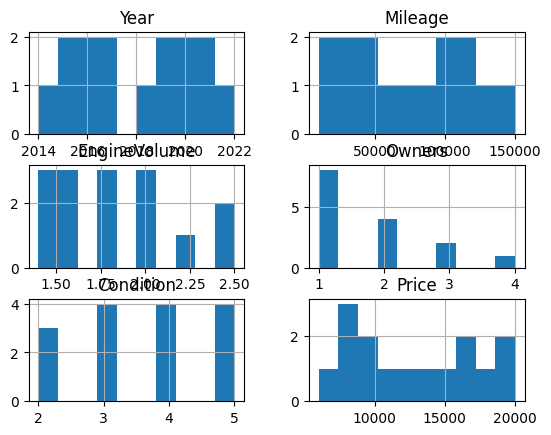

In [220]:


df = df['Year,Mileage,EngineVolume,Owners,Condition,Price'].str.split(',', expand=True)

df.columns = ['Year', 'Mileage', 'EngineVolume', 'Owners', 'Condition', 'Price']

df = df.astype(float)

df.hist()
plt.show()

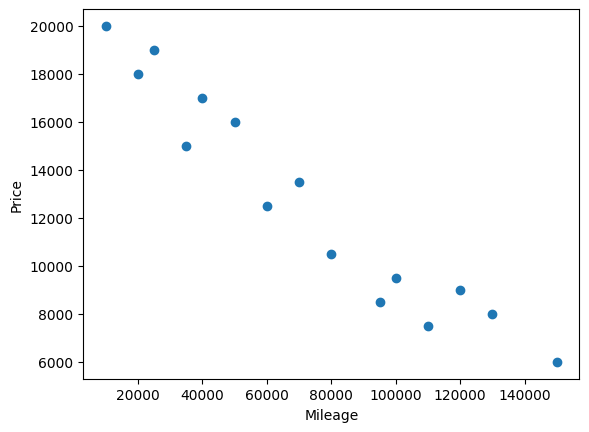

In [221]:
plt.scatter(df["Mileage"], df["Price"])
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

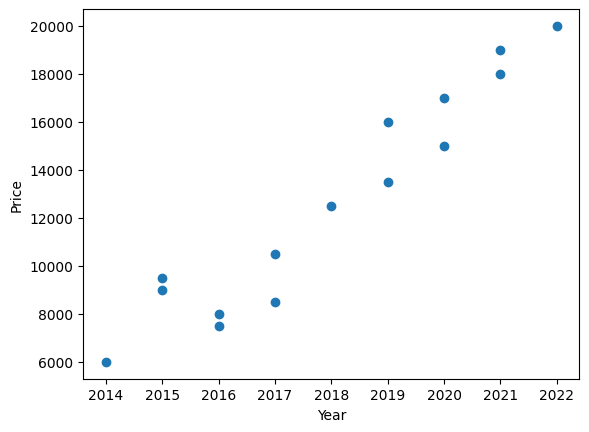

In [222]:
plt.scatter(df["Year"], df["Price"])
plt.xlabel("Year")
plt.ylabel("Price")
plt.show()

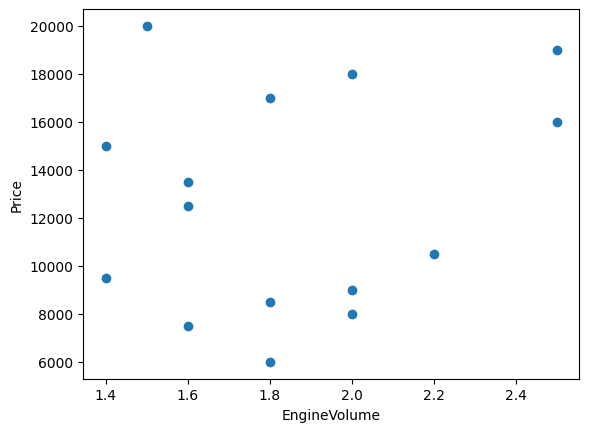

In [223]:
plt.scatter(df["EngineVolume"], df["Price"])
plt.xlabel("EngineVolume")
plt.ylabel("Price")
plt.show()

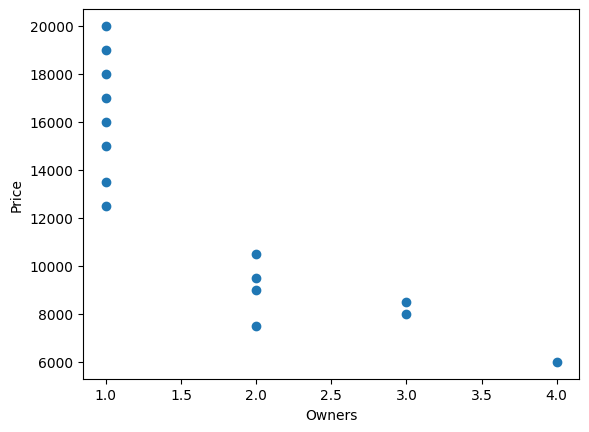

In [224]:
plt.scatter(df["Owners"], df["Price"])
plt.xlabel("Owners")
plt.ylabel("Price")
plt.show()

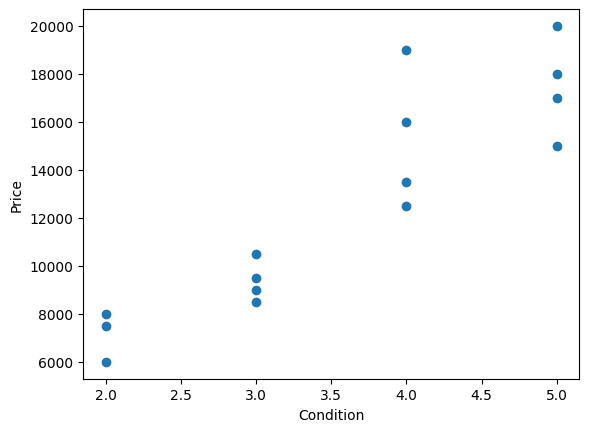

In [225]:
plt.scatter(df["Condition"], df["Price"])
plt.xlabel("Condition")
plt.ylabel("Price")
plt.show()

In [226]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [228]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2
)

In [229]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [232]:
y_pred = model.predict(X_test)

In [233]:
from sklearn.metrics import mean_squared_error, r2_score

print(mean_squared_error(y_test, y_pred))
print(r2_score(y_test, y_pred))

2826198.0210810765
0.8756196469939869


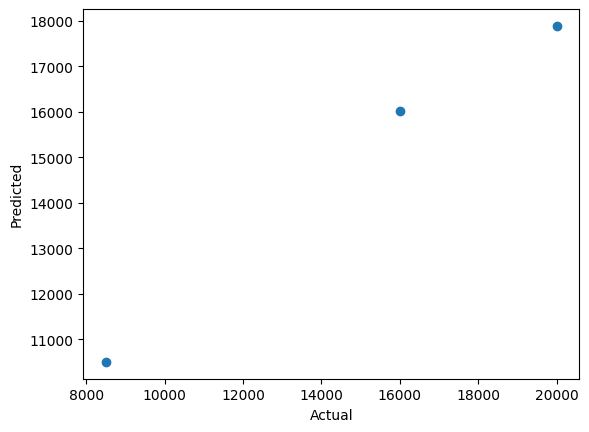

In [234]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()





## 1. What is regression?

Regression is a machine learning method used to **predict a number**.

 Examples:

* House price
* Salary
* Temperature
 The output is always a continuous value (a number).

---

## 2. Difference between regression, classification, and clustering

* **Regression**: predicts a number (e.g. 50000)
* **Classification**: predicts a category (e.g. Yes / No)
* **Clustering**: groups similar data without labels

---

## 3. Linear regression equation

A simple form is:

 y = mx + b

Meaning:

* x = input
* y = output
* m and b = values learned by the model

---

## 4. Polynomial regression: advantages and disadvantages

### Advantages:

* Can learn complex (non-linear) relationships
* More flexible than linear regression

###  Disadvantages:

* Can overfit the data
* Becomes more complex and harder to interpret

---

## 5. Purpose of `mean_squared_error`

It measures **how wrong the model is**.

 Lower value = better model

---

## 6. `fetch_california_housing` dataset

It contains data about houses in California.

 Features include:

* Income
* House age
* Number of rooms
* Population

 Target:

* Median house price

 The goal is to predict house prices

---

## 7. Setting test size in `train_test_split`

```python
train_test_split(X, y, test_size=0.2)
```

 Meaning:

* 20% test data
* 80% training data

---

## 8. Training a linear regression model

```python
model.fit(X_train, y_train)
```

 This means:
 The model learns from the training data

---

## 9. Difference in `predict` (Linear vs Polynomial)

* **Linear regression**: predicts directly from original data
* **Polynomial regression**: must first transform data (add powers like x², x³)

---

## 10. How to evaluate a regression model

We check the error using metrics:

* **MSE**: average squared error
* **MAE**: average absolute error
* **RMSE**: square root of MSE
* **R² score**: how well the model explains the data (closer to 1 is better)

---

##  Simple summary

Regression = predicting numbers
Good model = low error + high R²
Polynomial = more flexible but risky (overfitting)


